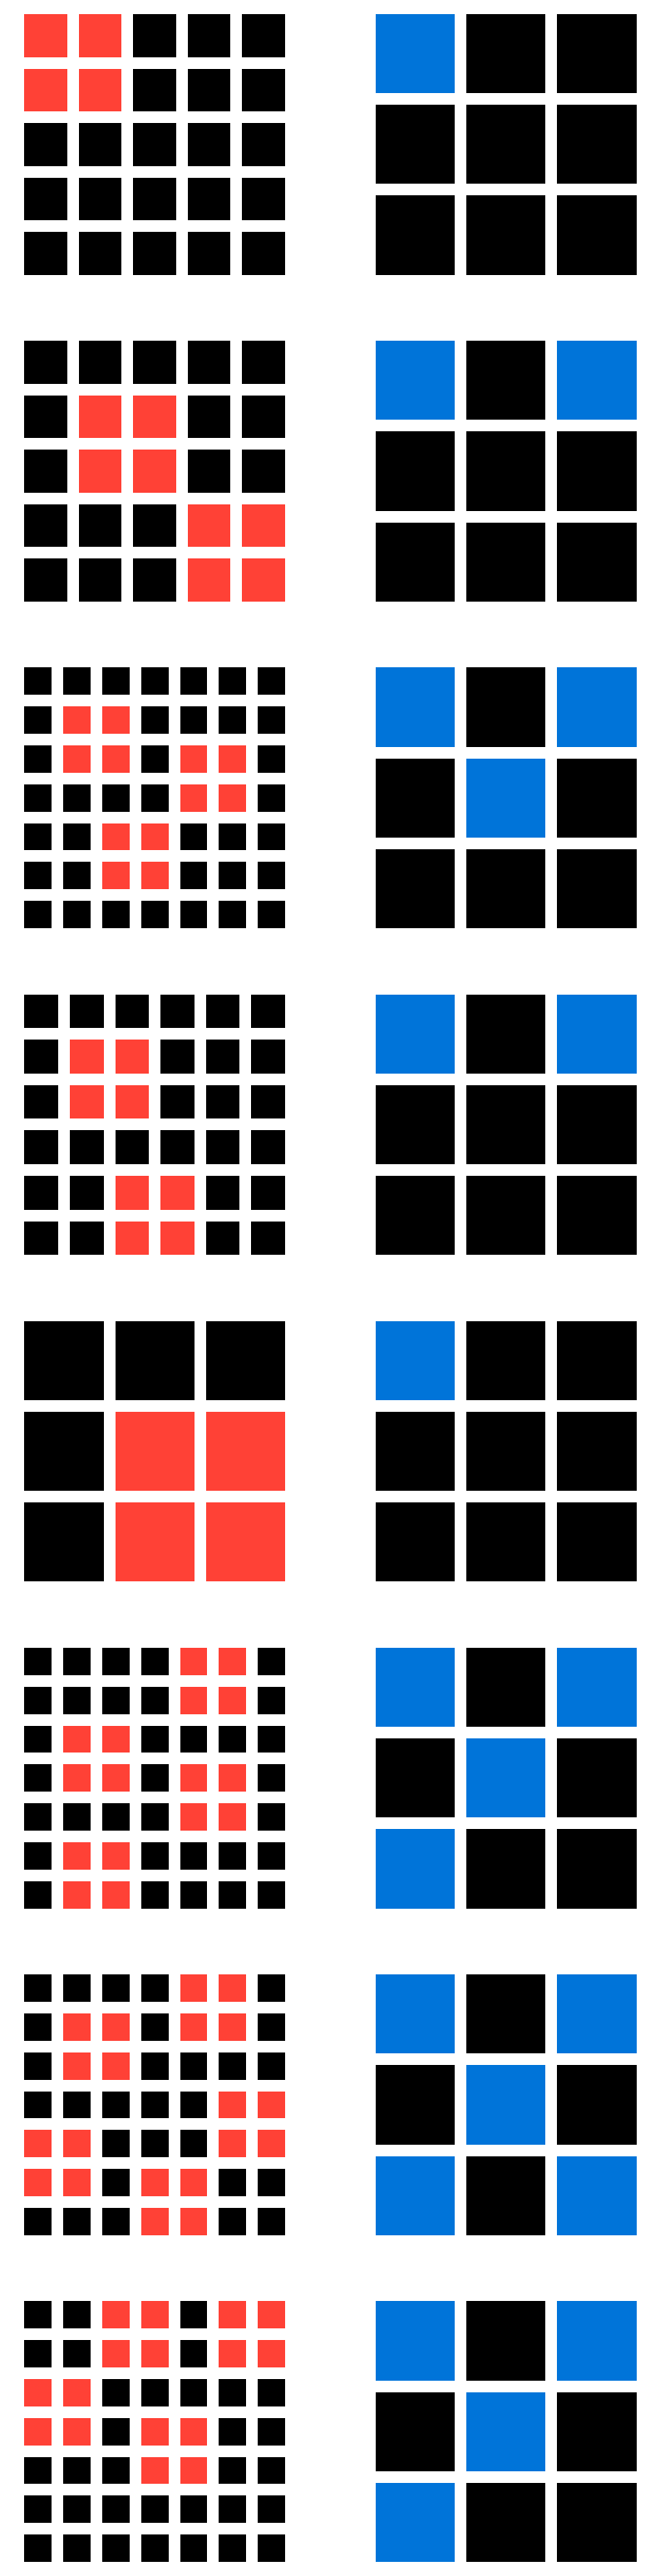

In [1]:
%load_ext autoreload
%autoreload 2

from image_utils import plot_all_Images
from task_utils import read_task


task_id='ff28f65a'
task = read_task(task_id, 'training')
plot_all_Images(task['train'])

In [15]:
from collections import defaultdict

color_names = ["black", "blue", "red", "green", "yellow", "grey", "fuschia", "orange", "teal", "brown"]

def color_counts(grid):
    """
    Count the number of red cells in the input grid.
    In this case, we'll assume:
    - 'R' represents red cells
    - 'B' represents black cells (or other colors)
    
    Args:
    grid (list of list): Input grid representing the cells.

    Returns:
    int: Number of red cells in the grid.
    """
    colors = defaultdict(int)
    for row in grid:
        for cell in row:
            colors[cell] += 1
    colors = dict(sorted(colors.items()))
    colors = {color_names[k]: v for k, v in colors.items()}
    return colors

In [17]:
for pair_i, pair in enumerate(task['train'], 1):
    inp, out = pair['input'], pair['output']
    inp_f = color_counts(inp)
    inp_s = f'{len(inp)}x{len(inp[0])}'
    out_f = color_counts(out)
    out_s = f'{len(out)}x{len(out[0])}'
    print(f'Pair #{pair_i}: count_red_cells(input[{inp_s}])={inp}, count_red_cells(output[{out_s}])={out}')


Pair #1: count_red_cells(input[5x5])=[[2, 2, 0, 0, 0], [2, 2, 0, 0, 0], [0, 0, 0, 0, 0], [0, 0, 0, 0, 0], [0, 0, 0, 0, 0]], count_red_cells(output[3x3])=[[1, 0, 0], [0, 0, 0], [0, 0, 0]]
Pair #2: count_red_cells(input[5x5])=[[0, 0, 0, 0, 0], [0, 2, 2, 0, 0], [0, 2, 2, 0, 0], [0, 0, 0, 2, 2], [0, 0, 0, 2, 2]], count_red_cells(output[3x3])=[[1, 0, 1], [0, 0, 0], [0, 0, 0]]
Pair #3: count_red_cells(input[7x7])=[[0, 0, 0, 0, 0, 0, 0], [0, 2, 2, 0, 0, 0, 0], [0, 2, 2, 0, 2, 2, 0], [0, 0, 0, 0, 2, 2, 0], [0, 0, 2, 2, 0, 0, 0], [0, 0, 2, 2, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0]], count_red_cells(output[3x3])=[[1, 0, 1], [0, 1, 0], [0, 0, 0]]
Pair #4: count_red_cells(input[6x6])=[[0, 0, 0, 0, 0, 0], [0, 2, 2, 0, 0, 0], [0, 2, 2, 0, 0, 0], [0, 0, 0, 0, 0, 0], [0, 0, 2, 2, 0, 0], [0, 0, 2, 2, 0, 0]], count_red_cells(output[3x3])=[[1, 0, 1], [0, 0, 0], [0, 0, 0]]
Pair #5: count_red_cells(input[3x3])=[[0, 0, 0], [0, 2, 2], [0, 2, 2]], count_red_cells(output[3x3])=[[1, 0, 0], [0, 0, 0], [0, 0, 0]]
Pair #

In [5]:
def map_clusters(grid):
    """
    Map clusters of red cells (contiguous red cells) in the input grid.
    Clusters are identified by adjacent red cells (up, down, left, right).

    Args:
    grid (list of list): Input grid representing the cells.

    Returns:
    list of list of tuples: List of clusters, each cluster is a list of coordinates (row, col).
    """
    visited = set()
    clusters = []

    def dfs(r, c, cluster):
        # Depth-first search to find all connected red cells
        if (r, c) in visited or grid[r][c] != 2:
            return
        visited.add((r, c))
        cluster.append((r, c))
        
        # Explore neighbors: up, down, left, right
        if r > 0: dfs(r-1, c, cluster)  # up
        if r < len(grid) - 1: dfs(r+1, c, cluster)  # down
        if c > 0: dfs(r, c-1, cluster)  # left
        if c < len(grid[0]) - 1: dfs(r, c+1, cluster)  # right

    for i in range(len(grid)):
        for j in range(len(grid[0])):
            if grid[i][j] == 2 and (i, j) not in visited:
                cluster = []
                dfs(i, j, cluster)
                if cluster:
                    clusters.append(cluster)

    return clusters


In [6]:
for pair_i, pair in enumerate(task['train'], 1):
    inp = map_clusters(pair['input'])
    out = map_clusters(pair['output'])
    print(f'Pair #{pair_i}: count_red_cells(input)={inp}, count_red_cells(output)={out}')

Pair #1: count_red_cells(input)=[[(0, 0), (1, 0), (1, 1), (0, 1)]], count_red_cells(output)=[]
Pair #2: count_red_cells(input)=[[(1, 1), (2, 1), (2, 2), (1, 2)], [(3, 3), (4, 3), (4, 4), (3, 4)]], count_red_cells(output)=[]
Pair #3: count_red_cells(input)=[[(1, 1), (2, 1), (2, 2), (1, 2)], [(2, 4), (3, 4), (3, 5), (2, 5)], [(4, 2), (5, 2), (5, 3), (4, 3)]], count_red_cells(output)=[]
Pair #4: count_red_cells(input)=[[(1, 1), (2, 1), (2, 2), (1, 2)], [(4, 2), (5, 2), (5, 3), (4, 3)]], count_red_cells(output)=[]
Pair #5: count_red_cells(input)=[[(1, 1), (2, 1), (2, 2), (1, 2)]], count_red_cells(output)=[]
Pair #6: count_red_cells(input)=[[(0, 4), (1, 4), (1, 5), (0, 5)], [(2, 1), (3, 1), (3, 2), (2, 2)], [(3, 4), (4, 4), (4, 5), (3, 5)], [(5, 1), (6, 1), (6, 2), (5, 2)]], count_red_cells(output)=[]
Pair #7: count_red_cells(input)=[[(0, 4), (1, 4), (1, 5), (0, 5)], [(1, 1), (2, 1), (2, 2), (1, 2)], [(3, 5), (4, 5), (4, 6), (3, 6)], [(4, 0), (5, 0), (5, 1), (4, 1)], [(5, 3), (6, 3), (6, 4)

In [18]:
def transform_grid(input_grid):
    """
    Transforms the input grid to the output grid based on the hypothesis:
    - Detects all 2x2 red clusters (cells with value 2).
    - Maps detected clusters to specific positions in a 3x3 output grid.
    """
    # Initialize the output grid as a 3x3 grid filled with zeros
    output_grid = [[0 for _ in range(3)] for _ in range(3)]
    
    # Define the mapping of clusters to output grid positions
    cluster_positions = [
        (0, 0),  # First cluster
        (0, 2),  # Second cluster
        (1, 1),  # Third cluster
        (2, 0),  # Fourth cluster
        (2, 2)   # Fifth cluster
    ]
    
    clusters = []  # List to hold the top-left positions of detected clusters
    visited = set()  # Set to keep track of cells that are part of detected clusters
    rows = len(input_grid)
    cols = len(input_grid[0])

    # Detect 2x2 red clusters in the input grid
    for i in range(rows - 1):
        for j in range(cols - 1):
            # Check if the 2x2 block starting at (i, j) forms a red cluster
            if (input_grid[i][j] == 2 and input_grid[i][j+1] == 2 and
                input_grid[i+1][j] == 2 and input_grid[i+1][j+1] == 2):
                
                # Check if this cluster hasn't been counted yet
                if not any((i + di, j + dj) in visited for di in (0, 1) for dj in (0, 1)):
                    # Mark the cells of this cluster as visited
                    for di in (0, 1):
                        for dj in (0, 1):
                            visited.add((i + di, j + dj))
                    # Add the top-left position of this cluster to the list
                    clusters.append((i, j))
    
    # Map the detected clusters to the output grid positions
    for idx, cluster in enumerate(clusters):
        if idx < len(cluster_positions):
            x, y = cluster_positions[idx]
            output_grid[x][y] = 1  # Set the corresponding cell to 1 (blue)
    
    return output_grid


In [25]:
# transform_grid(task['train'][1]['input'])
for pair in task['test']:
    assert transform_grid(pair['input']) == pair['output']
print('all tests passed')

all tests passed
